# T22 · Ajuste do limiar de decisão

**Issue:** #22 · **Fase 4 · Avaliação e Interpretação**

Os modelos devolvem uma **probabilidade** de doença. Por padrão, quem tem probabilidade ≥ 0,5 é sinalizado. Num sistema de **apoio à triagem**, deixar de sinalizar um doente (falso negativo) é o erro mais grave, então vale baixar esse corte: o recall sobe, ao custo de mais falsos positivos (encaminhamentos desnecessários).

**Regra:** o **maior limiar que mantém o recall ≥ 0,80 na validação**, ou seja, sinalizar pelo menos 8 em cada 10 doentes com o menor número possível de alarmes falsos. A regra e o recall mínimo estão em `config.THRESHOLD_MIN_RECALL`, e as funções em `cardio.models.evaluate` (`threshold_curve()`, `choose_threshold()`, `impact_per_1000()`).

> Tudo aqui usa só **treino** (para ajustar os modelos) e **validação** (para escolher o limiar). O teste fica para a T23.

In [1]:
import pkgutil
import sys
from importlib import import_module
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from IPython.display import Image, Markdown, display
from sklearn.metrics import roc_auc_score

from cardio.config import FIGURES_DIR, THRESHOLD_MIN_RECALL, THRESHOLDS_PATH
from cardio.data.preprocessing import load_splits
from cardio.models import estimators
from cardio.models.evaluate import choose_threshold, impact_per_1000, threshold_curve
from cardio.visualization.plots import plot_threshold_curve

pd.set_option("display.width", 200)


def pct(valor: float, casas: int = 1) -> str:
    return f"{valor * 100:.{casas}f}%".replace(".", ",")


def num(valor: float, casas: int = 2) -> str:
    return f"{valor:.{casas}f}".replace(".", ",")


def texto(conteudo: str) -> None:
    display(Markdown(conteudo))

## 1. Probabilidades na validação de cada modelo

Cada modelo de `models/estimators/` (exceto o `example`, que é o sorteio) é treinado no **treino** com os hiperparâmetros padrão do seu arquivo e gera as probabilidades da **validação**.

In [2]:
MODELOS = [m.name for m in pkgutil.iter_modules(estimators.__path__) if m.name != "example"]
print("Modelos encontrados:", MODELOS)

probas = {}  # (modelo, conjunto) -> (y_val, probabilidades)
for conjunto in "AB":
    X_train, X_val, _, y_train, y_val, _ = load_splits(conjunto, save_ids=False)
    for nome in MODELOS:
        modelo = import_module(f"cardio.models.estimators.{nome}").build_model(X_train).fit(X_train, y_train)
        probas[(nome, conjunto)] = (y_val, modelo.predict_proba(X_val)[:, 1])
print(f"{len(probas)} combinações de modelo × conjunto avaliadas na validação")

Modelos encontrados: ['knn', 'logistic', 'random_forest', 'xgb']


8 combinações de modelo × conjunto avaliadas na validação


## 2. Limiar escolhido para cada modelo

In [3]:
linhas = []
for (nome, conjunto), (y_val, proba) in probas.items():
    limiar = choose_threshold(y_val, proba)
    padrao, ajustado = impact_per_1000(y_val, proba, 0.5), impact_per_1000(y_val, proba, limiar)
    linhas.append({
        "modelo": nome, "features": conjunto, "auc_roc": roc_auc_score(y_val, proba), "limiar": limiar,
        "recall_0.5": padrao["recall"], "recall_ajustado": ajustado["recall"],
        "precision_0.5": padrao["precision"], "precision_ajustado": ajustado["precision"],
        "f1_0.5": padrao["f1"], "f1_ajustado": ajustado["f1"],
        "doentes_perdidos_1000_0.5": padrao["doentes_nao_sinalizados_por_1000"],
        "doentes_perdidos_1000_ajustado": ajustado["doentes_nao_sinalizados_por_1000"],
        "encaminhados_sem_doenca_1000_0.5": padrao["saudaveis_encaminhados_por_1000"],
        "encaminhados_sem_doenca_1000_ajustado": ajustado["saudaveis_encaminhados_por_1000"],
    })
limiares = pd.DataFrame(linhas).sort_values("auc_roc", ascending=False).reset_index(drop=True)

# Arquivo usado pela T23: o limiar de cada modelo × conjunto, escolhido na validação
THRESHOLDS_PATH.parent.mkdir(parents=True, exist_ok=True)
limiares.assign(min_recall=THRESHOLD_MIN_RECALL)[["modelo", "features", "limiar", "min_recall", "auc_roc"]].to_csv(
    THRESHOLDS_PATH, index=False)
print(f"Limiares salvos em {THRESHOLDS_PATH.relative_to(ROOT)}")
limiares.round(3)

Limiares salvos em results/thresholds.csv


,modelo,features,auc_roc,limiar,recall_0.5,recall_ajustado,precision_0.5,precision_ajustado,f1_0.5,f1_ajustado,doentes_perdidos_1000_0.5,doentes_perdidos_1000_ajustado,encaminhados_sem_doenca_1000_0.5,encaminhados_sem_doenca_1000_ajustado
0,xgb,B,0.792,0.36,0.677,0.811,0.745,0.660,0.709,0.728,159.872,93.607,114.625,206.675
1,xgb,A,0.792,0.36,0.677,0.815,0.747,0.658,0.711,0.728,159.677,91.369,113.457,209.497
2,random_forest,A,0.791,0.38,0.673,0.802,0.752,0.667,0.711,0.728,161.623,97.888,109.760,198.210
3,random_forest,B,0.789,0.37,0.658,0.812,0.761,0.661,0.706,0.729,169.407,93.023,102.073,206.189
4,knn,B,0.786,0.36,0.658,0.803,0.753,0.661,0.702,0.725,169.310,97.402,106.646,203.659
5,knn,A,0.785,0.35,0.660,0.811,0.753,0.652,0.704,0.723,168.142,93.510,106.938,213.876
6,logistic,B,0.785,0.37,0.654,0.806,0.758,0.660,0.702,0.726,171.159,95.845,103.435,205.605
7,logistic,A,0.783,0.39,0.671,0.807,0.750,0.658,0.708,0.725,162.791,95.456,110.538,207.940


In [4]:
faixa = limiares["limiar"]
texto(f"""**Interpretação:** em todos os modelos, o limiar que garante recall ≥ {num(THRESHOLD_MIN_RECALL)} fica entre
**{num(faixa.min())} e {num(faixa.max())}**, bem abaixo do 0,5 padrão. Com 0,5, o recall fica entre
{pct(limiares["recall_0.5"].min())} e {pct(limiares["recall_0.5"].max())}, ou seja, cerca de **1 em cada 3 doentes não seria sinalizado**.

O F1 {"melhora" if (limiares["f1_ajustado"] >= limiares["f1_0.5"]).all() else "varia pouco"} com o limiar ajustado
(de {pct(limiares["f1_0.5"].mean())} para {pct(limiares["f1_ajustado"].mean())}, em média): o ganho de recall compensa a perda de precision.""")

**Interpretação:** em todos os modelos, o limiar que garante recall ≥ 0,80 fica entre
**0,35 e 0,39**, bem abaixo do 0,5 padrão. Com 0,5, o recall fica entre
65,4% e 67,7%, ou seja, cerca de **1 em cada 3 doentes não seria sinalizado**.

O F1 melhora com o limiar ajustado
(de 70,7% para 72,7%, em média): o ganho de recall compensa a perda de precision.

## 3. Curva do melhor modelo na validação (`threshold.png`)

O gráfico usa o modelo com maior AUC na validação. A escolha do modelo final é da T23; se ela escolher outro, o limiar dele já está em `results/thresholds.csv`.

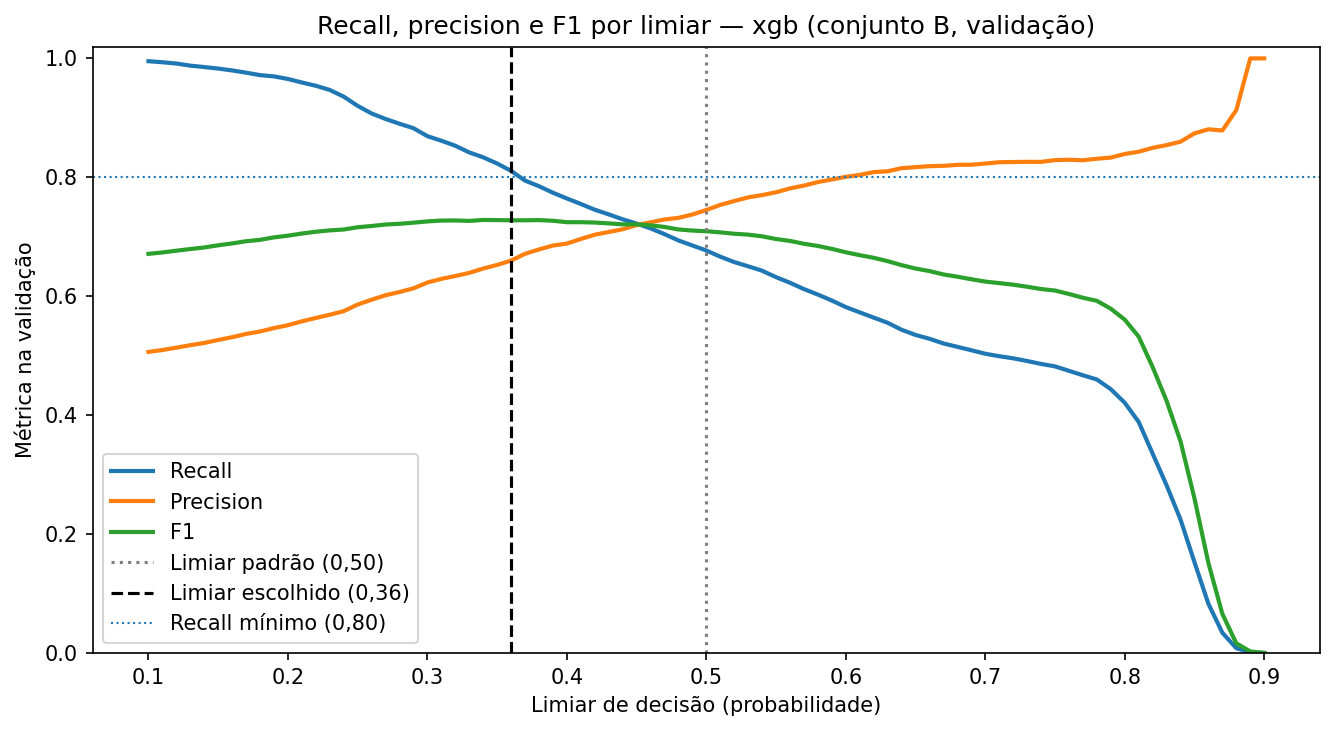

In [5]:
melhor = limiares.iloc[0]
y_val, proba = probas[(melhor["modelo"], melhor["features"])]
curva = threshold_curve(y_val, proba)
caminho = plot_threshold_curve(
    curva, melhor["limiar"], FIGURES_DIR / "threshold.png", min_recall=THRESHOLD_MIN_RECALL,
    title=f"Recall, precision e F1 por limiar — {melhor['modelo']} (conjunto {melhor['features']}, validação)",
)
display(Image(filename=str(caminho)))

## 4. Impacto em números: a cada 1.000 pacientes

In [6]:
comparacao = pd.DataFrame({
    "Limiar 0,50": impact_per_1000(y_val, proba, 0.5),
    f"Limiar ajustado ({num(melhor['limiar'])})": impact_per_1000(y_val, proba, melhor["limiar"]),
}).T[["recall", "precision", "f1", "especificidade",
      "doentes_nao_sinalizados_por_1000", "saudaveis_encaminhados_por_1000"]]
comparacao.round(3)

,recall,precision,f1,especificidade,doentes_nao_sinalizados_por_1000,saudaveis_encaminhados_por_1000
"Limiar 0,50",0.677,0.745,0.709,0.773,159.872,114.625
"Limiar ajustado (0,36)",0.811,0.660,0.728,0.591,93.607,206.675


In [7]:
p, a = comparacao.iloc[0], comparacao.iloc[1]
menos_perdidos = p["doentes_nao_sinalizados_por_1000"] - a["doentes_nao_sinalizados_por_1000"]
mais_encaminhados = a["saudaveis_encaminhados_por_1000"] - p["saudaveis_encaminhados_por_1000"]
texto(f"""### Justificativa do limiar ({melhor['modelo']}, conjunto {melhor['features']})

A cada **1.000 pacientes** avaliados na triagem:

| | Limiar 0,50 | Limiar {num(melhor['limiar'])} | Diferença |
|---|---|---|---|
| Doentes **não sinalizados** (falsos negativos) | {p["doentes_nao_sinalizados_por_1000"]:.0f} | **{a["doentes_nao_sinalizados_por_1000"]:.0f}** | **{-menos_perdidos:+.0f}** |
| Saudáveis encaminhados sem necessidade (falsos positivos) | {p["saudaveis_encaminhados_por_1000"]:.0f} | {a["saudaveis_encaminhados_por_1000"]:.0f} | {mais_encaminhados:+.0f} |
| Recall | {pct(p["recall"])} | **{pct(a["recall"])}** | |
| Precision | {pct(p["precision"])} | {pct(a["precision"])} | |

Com o limiar ajustado, **{menos_perdidos:.0f} doentes a mais em cada 1.000** passam a ser sinalizados, em troca de
**{mais_encaminhados:.0f} encaminhamentos extras** de pessoas saudáveis, ou seja, cerca de {num(mais_encaminhados / menos_perdidos, 1)} alarmes
falsos para cada doente a mais encontrado.

A troca vale a pena porque os dois erros não têm o mesmo custo: um doente não sinalizado pode ficar sem tratamento,
enquanto um falso positivo custa uma consulta ou um exame a mais, e **o médico sempre confirma o diagnóstico**. Por isso a regra
prioriza o recall (≥ {num(THRESHOLD_MIN_RECALL)}) e, entre os limiares que o atingem, fica com o maior, que é o que gera menos alarmes falsos.

**Para a T23:** o limiar foi escolhido na validação com o modelo treinado no treino. Na avaliação final, aplique o limiar do modelo
escolhido (`results/thresholds.csv`) às probabilidades do teste, **sem ajustá-lo de novo**.""")

### Justificativa do limiar (xgb, conjunto B)

A cada **1.000 pacientes** avaliados na triagem:

| | Limiar 0,50 | Limiar 0,36 | Diferença |
|---|---|---|---|
| Doentes **não sinalizados** (falsos negativos) | 160 | **94** | **-66** |
| Saudáveis encaminhados sem necessidade (falsos positivos) | 115 | 207 | +92 |
| Recall | 67,7% | **81,1%** | |
| Precision | 74,5% | 66,0% | |

Com o limiar ajustado, **66 doentes a mais em cada 1.000** passam a ser sinalizados, em troca de
**92 encaminhamentos extras** de pessoas saudáveis, ou seja, cerca de 1,4 alarmes
falsos para cada doente a mais encontrado.

A troca vale a pena porque os dois erros não têm o mesmo custo: um doente não sinalizado pode ficar sem tratamento,
enquanto um falso positivo custa uma consulta ou um exame a mais, e **o médico sempre confirma o diagnóstico**. Por isso a regra
prioriza o recall (≥ 0,80) e, entre os limiares que o atingem, fica com o maior, que é o que gera menos alarmes falsos.

**Para a T23:** o limiar foi escolhido na validação com o modelo treinado no treino. Na avaliação final, aplique o limiar do modelo
escolhido (`results/thresholds.csv`) às probabilidades do teste, **sem ajustá-lo de novo**.